<a href="https://colab.research.google.com/github/shalsaud/DS471-Project/blob/main/Breast_Cancer_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ==========================================
# 1. IMPORT LIBRARIES AND LOAD THE DATASET
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.datasets import load_breast_cancer

warnings.filterwarnings("ignore")

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load Breast Cancer Wisconsin Dataset
cancer = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["target"] = cancer.target

# Display dataset information
print("Dataset successfully loaded!")
print("=" * 50)

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget classes:")
print(dict(enumerate(cancer.target_names)))

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())


Dataset successfully loaded!
Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

In [2]:

# ==========================================
# 2. DATA QUALITY CHECK
# Missing Values and Duplicates
# ==========================================

# Check missing values
print("MISSING VALUES")
print("=" * 50)

missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDUPLICATE ANALYSIS")
print("=" * 50)

duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

# Check duplicate feature records without target
duplicate_features = df.drop(columns=["target"]).duplicated().sum()

print("Duplicate feature records:", duplicate_features)

# Display summary
print("\nDATA QUALITY SUMMARY")
print("=" * 50)

print("Total records:", len(df))
print("Total features:", len(df.columns) - 1)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", duplicate_rows)

if df.isnull().sum().sum() == 0 and duplicate_rows == 0:
    print("\nDataset is clean: no missing values or duplicate rows.")
else:
    print("\nFurther data cleaning is required.")


MISSING VALUES
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total missing values: 0

DUPLICATE ANALYSIS
Number of duplicate rows: 0


In [3]:

# ==========================================
# 3. OUTLIER DETECTION USING IQR
# ==========================================

# Select input features only
X = df.drop(columns=["target"])

# Calculate Q1 and Q3
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers for each feature
outlier_counts = (
    ((X < lower_bound) | (X > upper_bound))
    .sum()
)

# Display results
outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage": (
        outlier_counts / len(X) * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    by="Outlier Count",
    ascending=False
)

display(outlier_summary)

print("Total outlier observations across feature columns:",
      outlier_counts.sum())


,Outlier Count,Outlier Percentage
area error,65,11.42
radius error,38,6.68
perimeter error,38,6.68
worst area,35,6.15
smoothness error,30,5.27
fractal dimension error,28,4.92
compactness error,28,4.92
symmetry error,27,4.75
mean area,25,4.39
worst fractal dimension,24,4.22


Total outlier observations across feature columns: 608


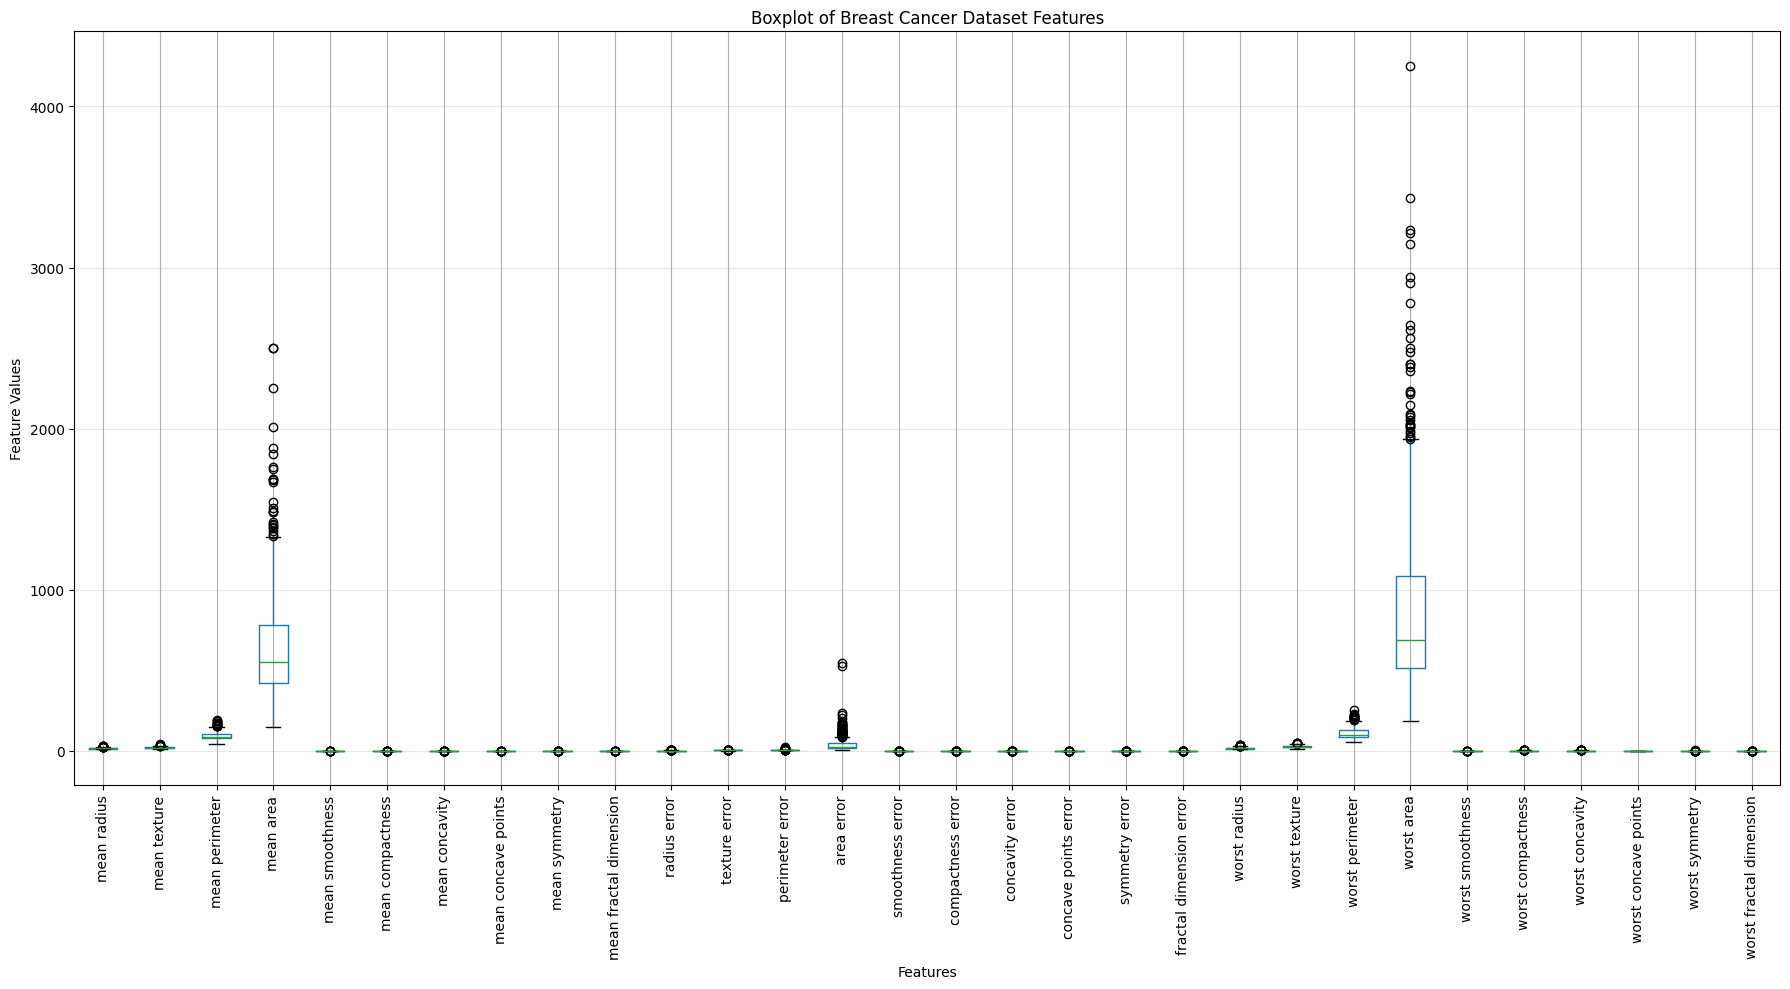

In [4]:

# ==========================================
# 4. OUTLIER VISUALIZATION
# ==========================================

import os

# Create figures folder
os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(18, 10))

X.boxplot(rot=90)

plt.title("Boxplot of Breast Cancer Dataset Features")
plt.ylabel("Feature Values")
plt.xlabel("Features")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/outlier_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Class counts:
Malignant: 212 (37.26%)
Benign: 357 (62.74%)


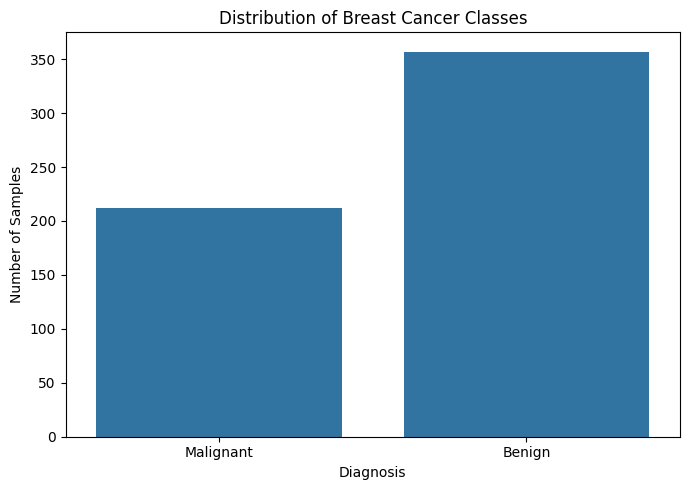

In [5]:

# Target class distribution
class_counts = df["target"].value_counts().sort_index()

class_names = {
    0: "Malignant",
    1: "Benign"
}

print("Class counts:")
for label, count in class_counts.items():
    print(f"{class_names[label]}: {count} ({count / len(df) * 100:.2f}%)")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="target")
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=300)
plt.show()


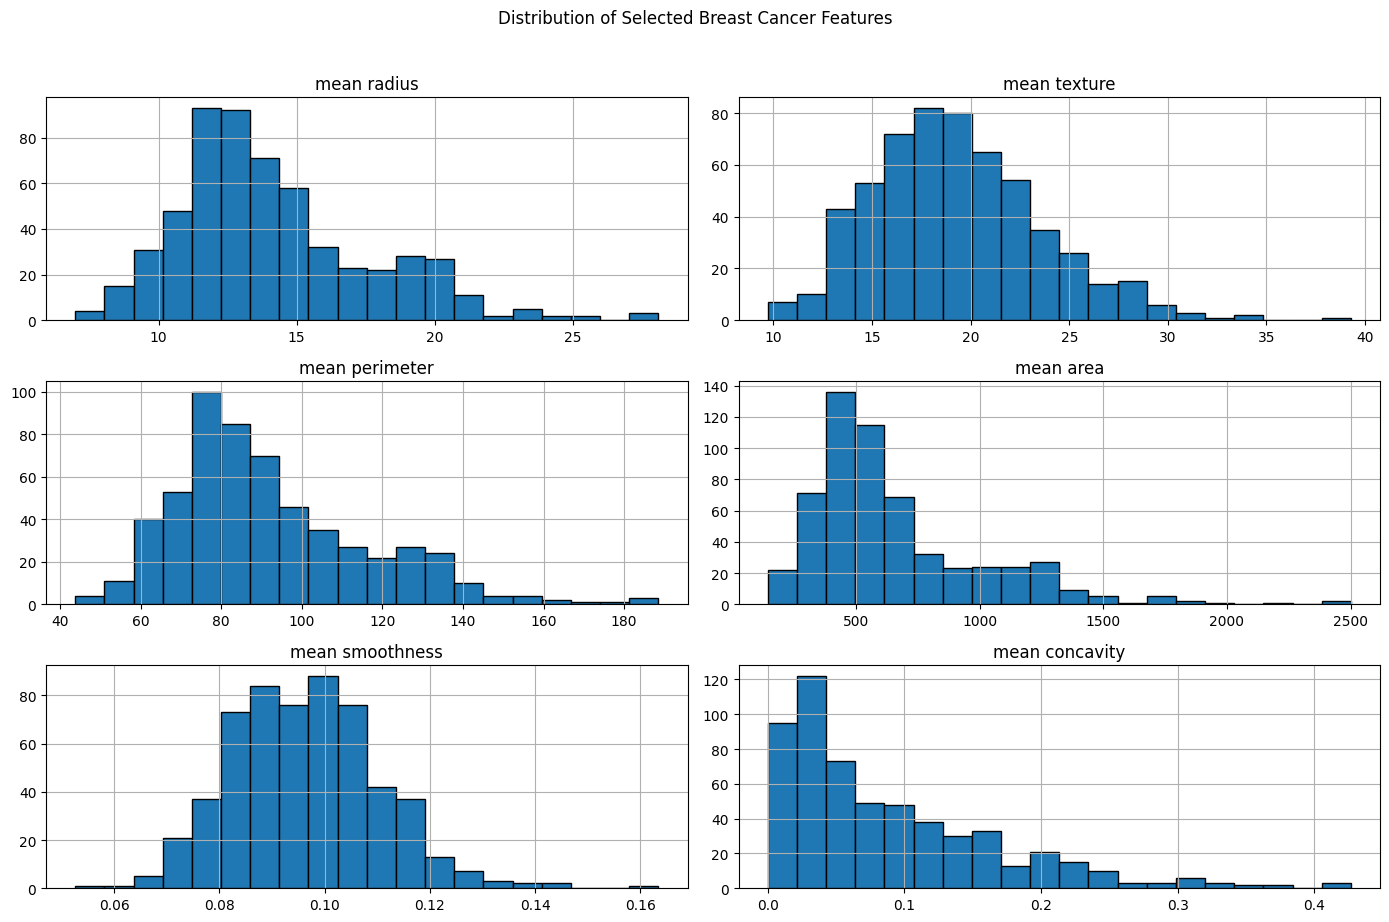

In [6]:

selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity"
]

df[selected_features].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Selected Breast Cancer Features", y=1.02)
plt.tight_layout()
plt.savefig("figures/feature_distributions.png", dpi=300)
plt.show()


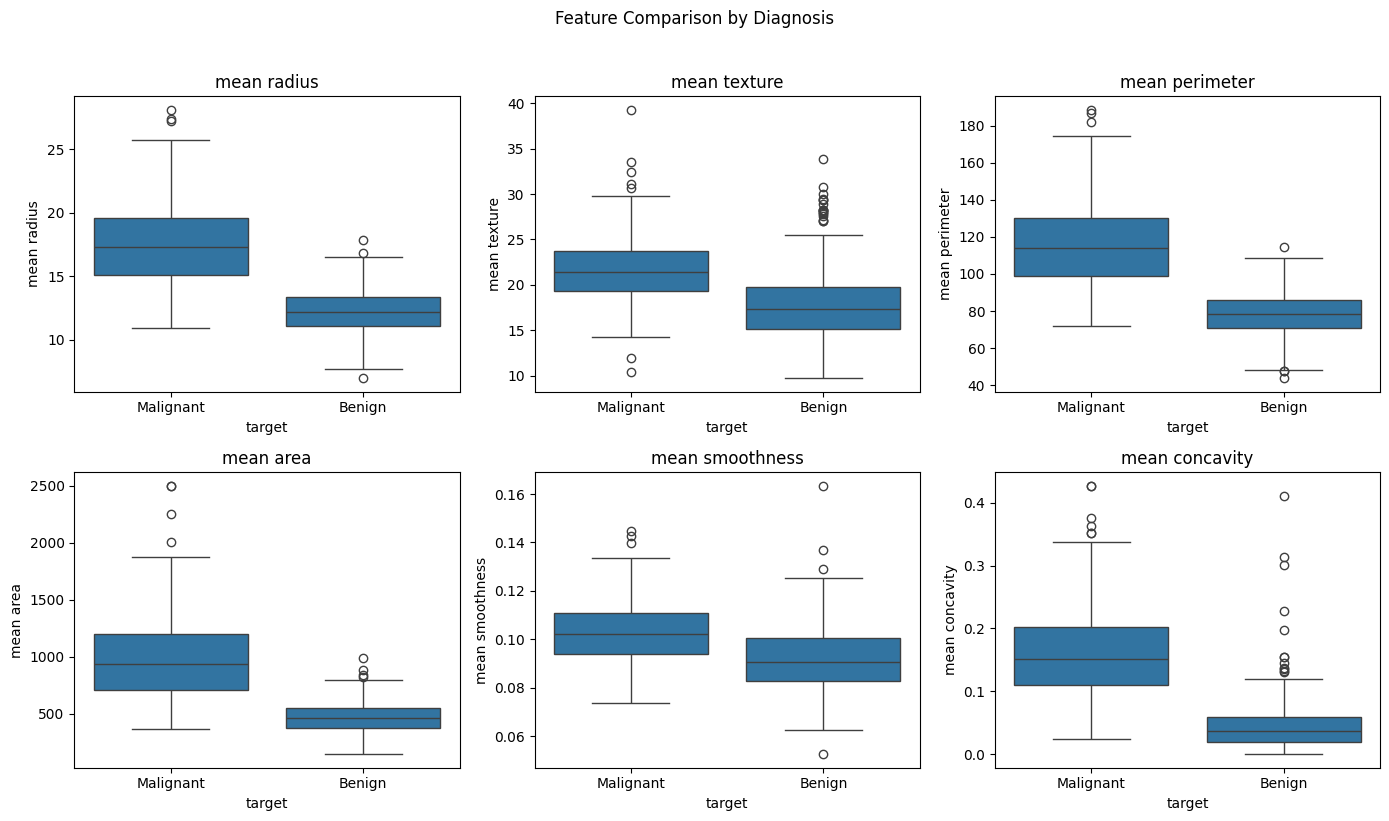

In [7]:

plt.figure(figsize=(14, 8))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df, x="target", y=feature)
    plt.xticks([0, 1], ["Malignant", "Benign"])
    plt.title(feature)

plt.suptitle("Feature Comparison by Diagnosis", y=1.02)
plt.tight_layout()
plt.savefig("figures/features_by_diagnosis.png", dpi=300)
plt.show()


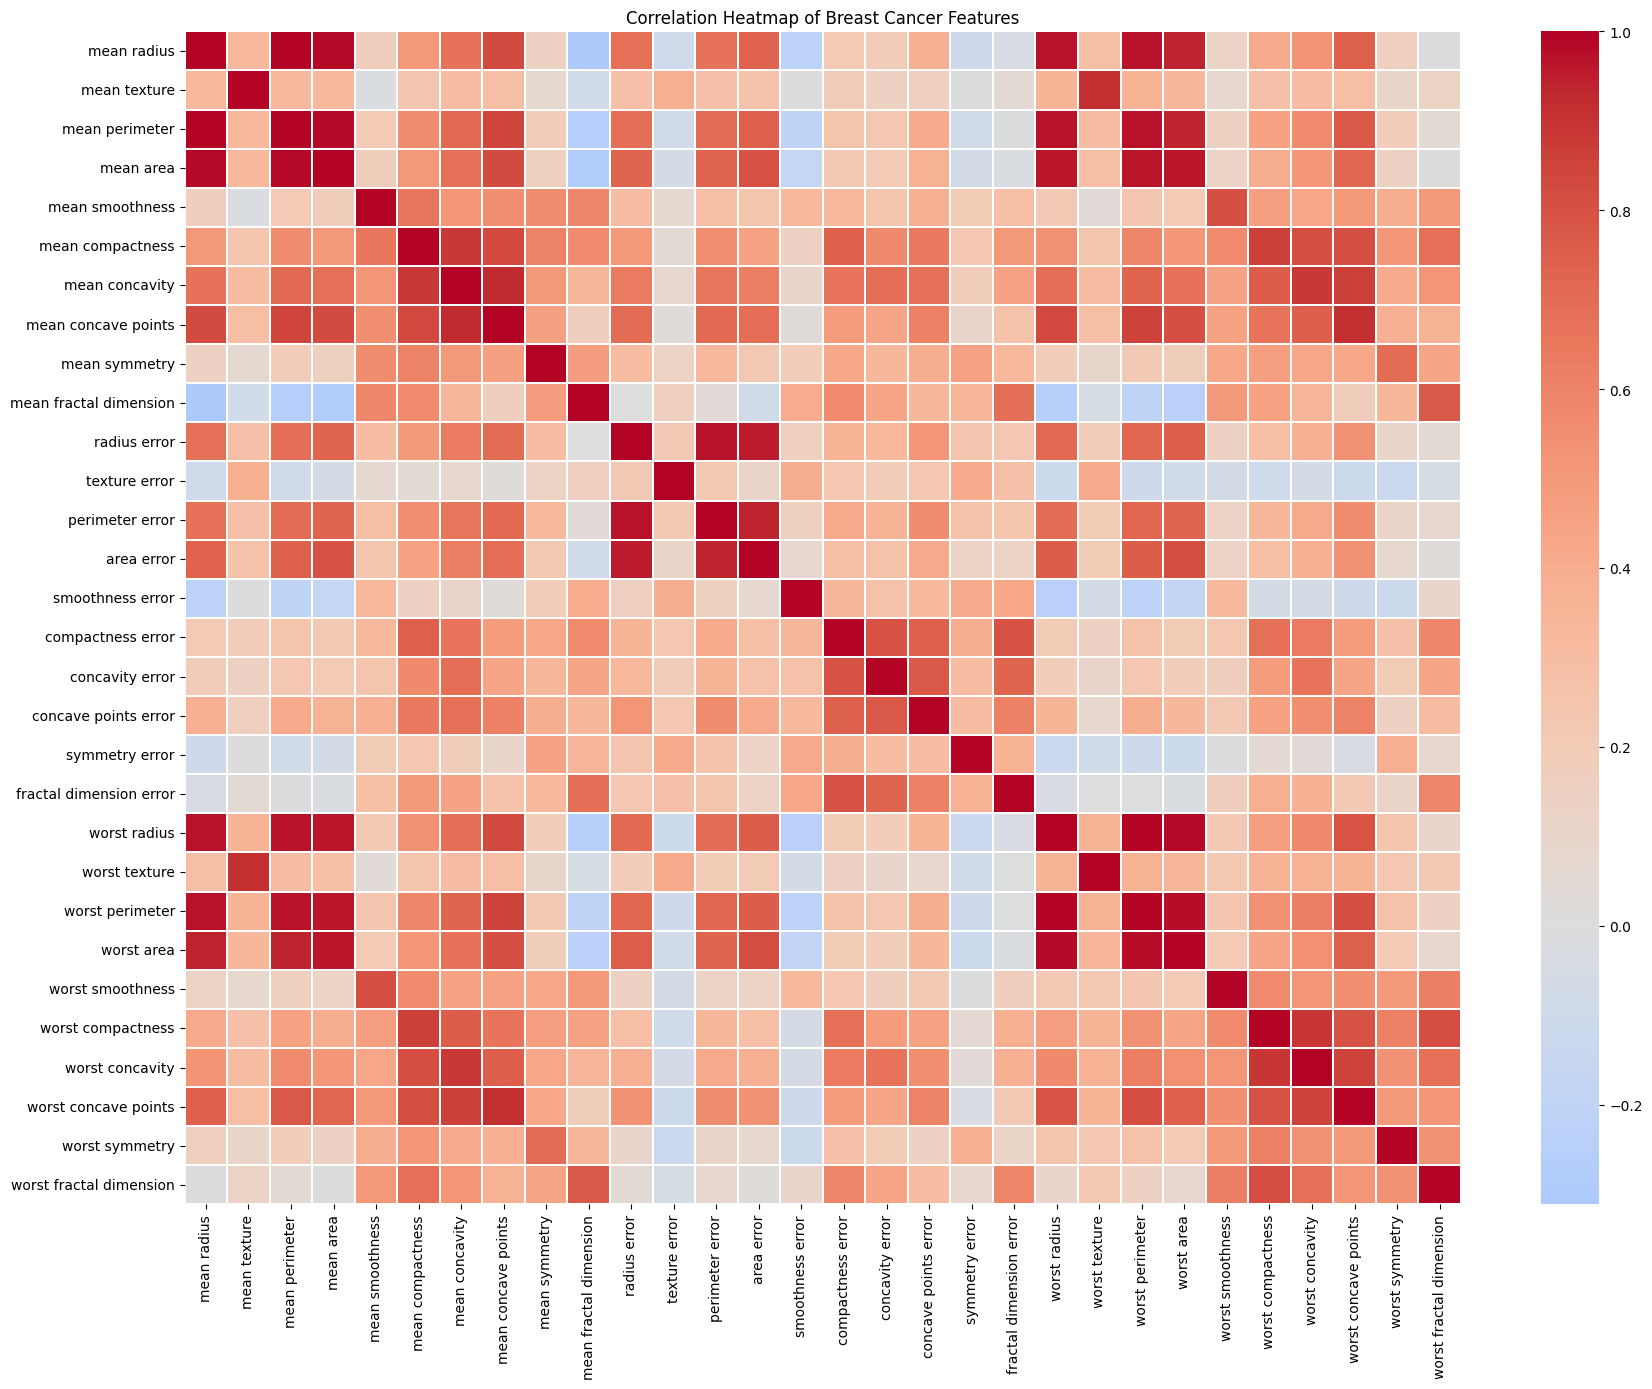

In [8]:

plt.figure(figsize=(18, 14))

correlation_matrix = df.drop(columns=["target"]).corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=300)
plt.show()


In [9]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["target"])
y = df["target"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTotal samples:", len(X_train) + len(X_val) + len(X_test))


Training set: (398, 30)
Validation set: (85, 30)
Testing set: (86, 30)

Total samples: 569


target,Benign (%),Malignant (%)
Training,62.81,37.19
Validation,62.35,37.65
Testing,62.79,37.21


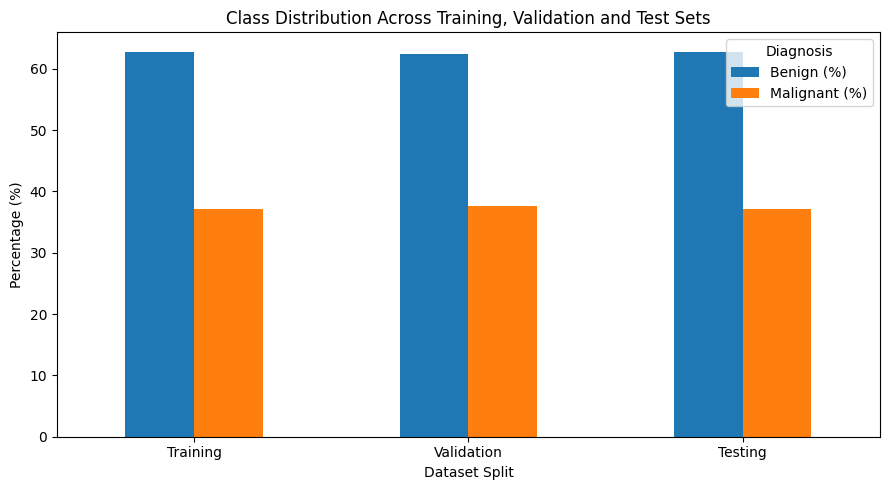

In [10]:

split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).T * 100

split_summary = split_summary.rename(
    columns={0: "Malignant (%)", 1: "Benign (%)"}
)

display(split_summary.round(2))

split_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Class Distribution Across Training, Validation and Test Sets")
plt.ylabel("Percentage (%)")
plt.xlabel("Dataset Split")
plt.xticks(rotation=0)
plt.legend(title="Diagnosis")
plt.tight_layout()

plt.savefig("figures/data_split_distribution.png", dpi=300)
plt.show()


In [11]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Validation data scaled:", X_val_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

print("\nTraining feature means (first 5):")
print(X_train_scaled.mean(axis=0)[:5].round(4))

print("\nTraining feature standard deviations (first 5):")
print(X_train_scaled.std(axis=0)[:5].round(4))


Training data scaled: (398, 30)
Validation data scaled: (85, 30)
Testing data scaled: (86, 30)

Training feature means (first 5):
[-0.  0.  0.  0.  0.]

Training feature standard deviations (first 5):
[1. 1. 1. 1. 1.]


In [12]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build the model
nn_model = Sequential([
    Input(shape=(30,)),
    Dense(32, activation="relu"),
    Dropout(0.30),

    Dense(16, activation="relu"),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

# Compile the model
nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
nn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# Reduce learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Train the neural network
history = nn_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Training completed!")
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7362 - loss: 0.5517 - val_accuracy: 0.9529 - val_loss: 0.3950 - learning_rate: 0.0010
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9121 - loss: 0.3436 - val_accuracy: 0.9647 - val_loss: 0.2490 - learning_rate: 0.0010
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9422 - loss: 0.2206 - val_accuracy: 0.9765 - val_loss: 0.1646 - learning_rate: 0.0010
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9548 - loss: 0.1859 - val_accuracy: 0.9882 - val_loss: 0.1203 - learning_rate: 0.0010
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9447 - loss: 0.1615 - val_accuracy: 0.9882 - val_loss: 0.0937 - learning_rate: 0.0010
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9598 - loss: 0.1254 - val_accuracy: 0.9882 - val_loss: 0.0761 - learning_rate: 0.0010
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9548 - loss: 0.1173 - val_a

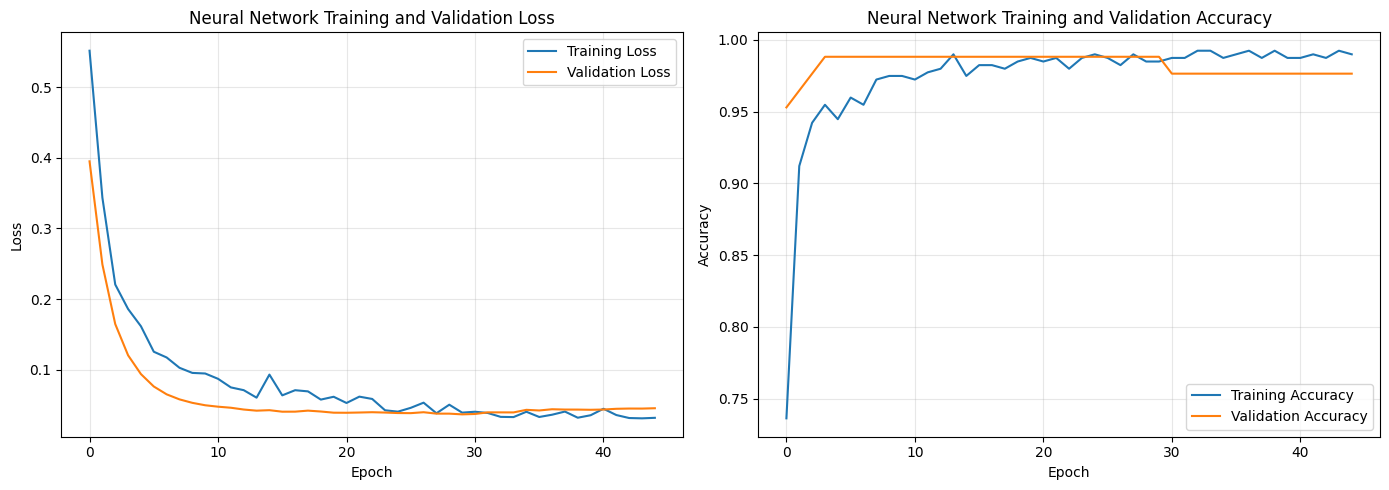

In [14]:

# Plot training and validation curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Neural Network Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curve
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Neural Network Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/neural_network_learning_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [15]:

val_loss, val_accuracy = nn_model.evaluate(
    X_val_scaled,
    y_val,
    verbose=0
)

print("Neural Network Validation Results")
print("----------------------------------")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy (%): {val_accuracy * 100:.2f}%")


Neural Network Validation Results
----------------------------------
Validation Loss: 0.0367
Validation Accuracy: 0.9882
Validation Accuracy (%): 98.82%


In [16]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using original, unscaled training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [17]:

from sklearn.metrics import accuracy_score, classification_report

# Predictions
rf_train_pred = rf_model.predict(X_train)
rf_val_pred = rf_model.predict(X_val)

# Accuracy
rf_train_accuracy = accuracy_score(y_train, rf_train_pred)
rf_val_accuracy = accuracy_score(y_val, rf_val_pred)

print("Random Forest Results")
print("---------------------")
print(f"Training Accuracy: {rf_train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {rf_val_accuracy * 100:.2f}%")

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    rf_val_pred,
    target_names=["Malignant", "Benign"]
))


Random Forest Results
---------------------
Training Accuracy: 100.00%
Validation Accuracy: 98.82%

Validation Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      1.00      0.98        32
      Benign       1.00      0.98      0.99        53

    accuracy                           0.99        85
   macro avg       0.98      0.99      0.99        85
weighted avg       0.99      0.99      0.99        85



,Feature,Importance
27,worst concave points,0.158955
23,worst area,0.146962
22,worst perimeter,0.085793
20,worst radius,0.078952
0,mean radius,0.077714
2,mean perimeter,0.074234
7,mean concave points,0.065869
6,mean concavity,0.054281
3,mean area,0.041657
26,worst concavity,0.031362


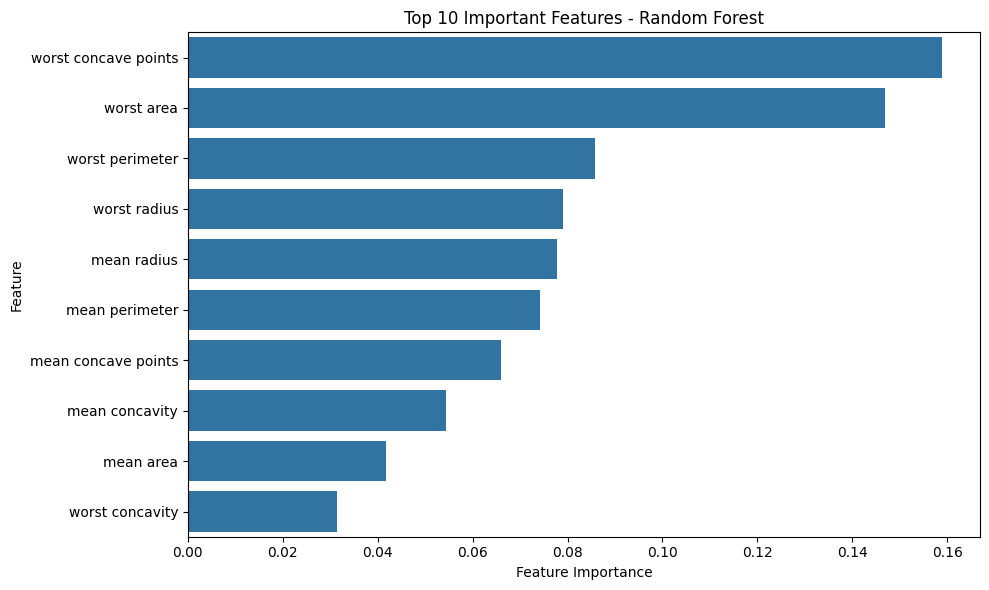

In [18]:

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
display(feature_importance.head(10))

# Plot top 10 features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("figures/random_forest_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [19]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM model training completed!")

SVM model training completed!


In [20]:
from sklearn.metrics import accuracy_score, classification_report

svm_train_pred = svm_model.predict(X_train_scaled)
svm_val_pred = svm_model.predict(X_val_scaled)

svm_train_accuracy = accuracy_score(y_train, svm_train_pred)
svm_val_accuracy = accuracy_score(y_val, svm_val_pred)

print("SVM Training Accuracy:", round(svm_train_accuracy, 4))
print("SVM Validation Accuracy:", round(svm_val_accuracy, 4))

print("\nSVM Validation Classification Report:")
print(classification_report(
    y_val,
    svm_val_pred,
    target_names=["Malignant", "Benign"]
))

SVM Training Accuracy: 0.9824
SVM Validation Accuracy: 0.9765

SVM Validation Classification Report:
              precision    recall  f1-score   support

   Malignant       0.94      1.00      0.97        32
      Benign       1.00      0.96      0.98        53

    accuracy                           0.98        85
   macro avg       0.97      0.98      0.98        85
weighted avg       0.98      0.98      0.98        85



In [21]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

svm_param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    "svm__kernel": ["rbf"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross-Validation F1 Macro Score:")
print(round(svm_grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best SVM Parameters:
{'svm__C': 10, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'}

Best Cross-Validation F1 Macro Score:
0.9782


In [22]:
from sklearn.metrics import accuracy_score, classification_report

best_svm = svm_grid.best_estimator_

svm_tuned_train_pred = best_svm.predict(X_train)
svm_tuned_val_pred = best_svm.predict(X_val)

print("Tuned SVM Training Accuracy:",
      round(accuracy_score(y_train, svm_tuned_train_pred), 4))

print("Tuned SVM Validation Accuracy:",
      round(accuracy_score(y_val, svm_tuned_val_pred), 4))

print("\nTuned SVM Validation Classification Report:")
print(classification_report(
    y_val,
    svm_tuned_val_pred,
    target_names=["Malignant", "Benign"]
))

Tuned SVM Training Accuracy: 0.9874
Tuned SVM Validation Accuracy: 0.9882

Tuned SVM Validation Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      1.00      0.98        32
      Benign       1.00      0.98      0.99        53

    accuracy                           0.99        85
   macro avg       0.98      0.99      0.99        85
weighted avg       0.99      0.99      0.99        85



In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1 Macro Score:")
print(round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Random Forest Parameters:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation F1 Macro Score:
0.9734


In [24]:
from sklearn.metrics import accuracy_score, classification_report

best_rf = rf_grid.best_estimator_

rf_tuned_train_pred = best_rf.predict(X_train)
rf_tuned_val_pred = best_rf.predict(X_val)

rf_tuned_train_accuracy = accuracy_score(
    y_train, rf_tuned_train_pred
)

rf_tuned_val_accuracy = accuracy_score(
    y_val, rf_tuned_val_pred
)

print("Tuned RF Training Accuracy:",
      round(rf_tuned_train_accuracy, 4))

print("Tuned RF Validation Accuracy:",
      round(rf_tuned_val_accuracy, 4))

print("\nTuned RF Validation Classification Report:")
print(classification_report(
    y_val,
    rf_tuned_val_pred,
    target_names=["Malignant", "Benign"]
))

print("\nTraining-validation accuracy gap:",
      round(rf_tuned_train_accuracy - rf_tuned_val_accuracy, 4))

Tuned RF Training Accuracy: 1.0
Tuned RF Validation Accuracy: 0.9765

Tuned RF Validation Classification Report:
              precision    recall  f1-score   support

   Malignant       0.94      1.00      0.97        32
      Benign       1.00      0.96      0.98        53

    accuracy                           0.98        85
   macro avg       0.97      0.98      0.98        85
weighted avg       0.98      0.98      0.98        85


Training-validation accuracy gap: 0.0235


,Feature,Importance
23,worst area,0.139520
27,worst concave points,0.127919
2,mean perimeter,0.100641
20,worst radius,0.086351
22,worst perimeter,0.074486
6,mean concavity,0.073585
7,mean concave points,0.055645
3,mean area,0.049049
0,mean radius,0.043714
26,worst concavity,0.035473


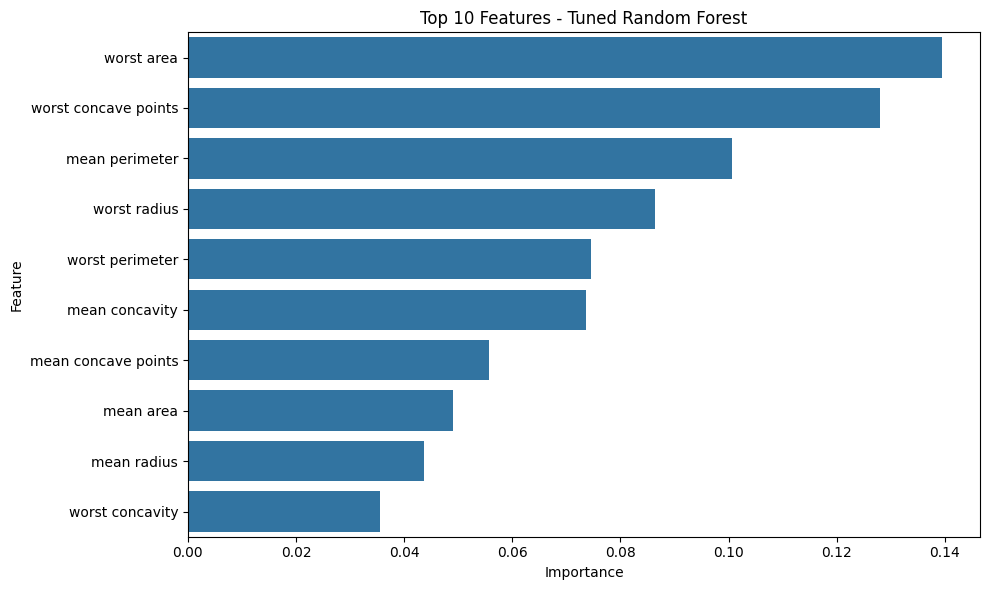

In [25]:
tuned_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(tuned_importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=tuned_importance.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Features - Tuned Random Forest")
plt.tight_layout()
plt.savefig(
    "figures/tuned_rf_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

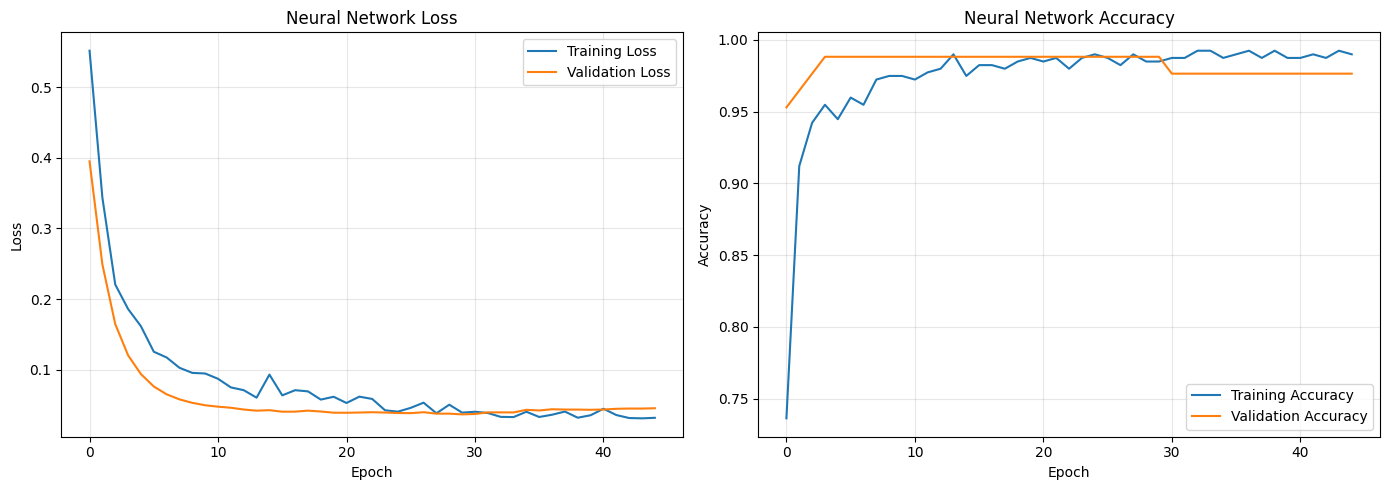

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curves
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/neural_network_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

tuned_nn = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.40),
    Dense(16, activation="relu"),
    Dropout(0.30),
    Dense(1, activation="sigmoid")
])

tuned_nn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop_tuned = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr_tuned = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

tuned_history = tuned_nn.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_tuned, reduce_lr_tuned],
    verbose=1
)

print("Tuned Neural Network training completed!")
print("Epochs completed:", len(tuned_history.history["loss"]))

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6809 - loss: 0.6001 - val_accuracy: 0.9529 - val_loss: 0.4202 - learning_rate: 0.0010
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8668 - loss: 0.3912 - val_accuracy: 0.9647 - val_loss: 0.2831 - learning_rate: 0.0010
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9246 - loss: 0.2573 - val_accuracy: 0.9765 - val_loss: 0.1927 - learning_rate: 0.0010
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9422 - loss: 0.2270 - val_accuracy: 0.9765 - val_loss: 0.1400 - learning_rate: 0.0010
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9422 - loss: 0.1885 - val_accuracy: 0.9882 - val_loss: 0.1077 - learning_rate: 0.0010
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9422 - loss: 0.1649 - val_accuracy: 0.9882 - val_loss: 0.0864 - learning_rate: 0.0010
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9472 - loss: 0.1491 - val

In [28]:
original_val_loss, original_val_acc = nn_model.evaluate(
    X_val_scaled, y_val, verbose=0
)

tuned_val_loss, tuned_val_acc = tuned_nn.evaluate(
    X_val_scaled, y_val, verbose=0
)

nn_comparison = pd.DataFrame({
    "Model": ["Original Neural Network", "Tuned Neural Network"],
    "Validation Loss": [original_val_loss, tuned_val_loss],
    "Validation Accuracy": [original_val_acc, tuned_val_acc]
})

display(nn_comparison.round(4))

,Model,Validation Loss,Validation Accuracy
0,Original Neural Network,0.0367,0.9882
1,Tuned Neural Network,0.0345,0.9882


In [29]:
from sklearn.metrics import accuracy_score, f1_score

# Predictions from all tuned models
nn_val_pred = (tuned_nn.predict(X_val_scaled, verbose=0).ravel() >= 0.5).astype(int)
rf_val_pred = best_rf.predict(X_val)
svm_val_pred = best_svm.predict(X_val)

# Comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Tuned Neural Network",
        "Tuned Random Forest",
        "Tuned SVM"
    ],
    "Validation Accuracy": [
        accuracy_score(y_val, nn_val_pred),
        accuracy_score(y_val, rf_val_pred),
        accuracy_score(y_val, svm_val_pred)
    ],
    "Validation F1 Macro": [
        f1_score(y_val, nn_val_pred, average="macro"),
        f1_score(y_val, rf_val_pred, average="macro"),
        f1_score(y_val, svm_val_pred, average="macro")
    ]
})

display(model_comparison.round(4))

,Model,Validation Accuracy,Validation F1 Macro
0,Tuned Neural Network,0.9882,0.9875
1,Tuned Random Forest,0.9765,0.9752
2,Tuned SVM,0.9882,0.9875


In [30]:
from sklearn.metrics import recall_score

print("Malignant Recall Comparison:")

print("Neural Network:",
      round(recall_score(y_val, nn_val_pred, pos_label=0), 4))

print("Random Forest:",
      round(recall_score(y_val, rf_val_pred, pos_label=0), 4))

print("SVM:",
      round(recall_score(y_val, svm_val_pred, pos_label=0), 4))

Malignant Recall Comparison:
Neural Network: 1.0
Random Forest: 1.0
SVM: 1.0


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Neural Network
nn_test_prob = tuned_nn.predict(
    X_test_scaled, verbose=0
).ravel()

nn_test_pred = (nn_test_prob >= 0.5).astype(int)

# Random Forest
rf_test_pred = best_rf.predict(X_test)
rf_test_prob = best_rf.predict_proba(X_test)[:, 1]

# SVM
svm_test_pred = best_svm.predict(X_test)
svm_test_scores = best_svm.decision_function(X_test)

# Evaluation function
def evaluate_model(name, y_true, y_pred, malignant_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Malignant)": precision_score(
            y_true, y_pred, pos_label=0
        ),
        "Recall (Malignant)": recall_score(
            y_true, y_pred, pos_label=0
        ),
        "F1-score (Malignant)": f1_score(
            y_true, y_pred, pos_label=0
        ),
        "ROC-AUC (Malignant)": roc_auc_score(
            (y_true == 0).astype(int),
            malignant_score
        )
    }

results = [
    evaluate_model(
        "Neural Network", y_test, nn_test_pred, 1 - nn_test_prob
    ),
    evaluate_model(
        "Random Forest", y_test, rf_test_pred, 1 - rf_test_prob
    ),
    evaluate_model(
        "SVM", y_test, svm_test_pred, -svm_test_scores
    )
]

final_results = pd.DataFrame(results)

display(final_results.round(4))

,Model,Accuracy,Precision (Malignant),Recall (Malignant),F1-score (Malignant),ROC-AUC (Malignant)
0,Neural Network,0.9535,0.9375,0.9375,0.9375,0.9942
1,Random Forest,0.9070,0.9000,0.8438,0.8710,0.9826
2,SVM,0.9535,1.0000,0.8750,0.9333,0.9931


In [33]:
print("NEURAL NETWORK")
print(classification_report(
    y_test, nn_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

print("\nRANDOM FOREST")
print(classification_report(
    y_test, rf_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

print("\nSVM")
print(classification_report(
    y_test, svm_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

NEURAL NETWORK
              precision    recall  f1-score   support

   Malignant       0.94      0.94      0.94        32
      Benign       0.96      0.96      0.96        54

    accuracy                           0.95        86
   macro avg       0.95      0.95      0.95        86
weighted avg       0.95      0.95      0.95        86


RANDOM FOREST
              precision    recall  f1-score   support

   Malignant       0.90      0.84      0.87        32
      Benign       0.91      0.94      0.93        54

    accuracy                           0.91        86
   macro avg       0.91      0.89      0.90        86
weighted avg       0.91      0.91      0.91        86


SVM
              precision    recall  f1-score   support

   Malignant       1.00      0.88      0.93        32
      Benign       0.93      1.00      0.96        54

    accuracy                           0.95        86
   macro avg       0.97      0.94      0.95        86
weighted avg       0.96      0.95      

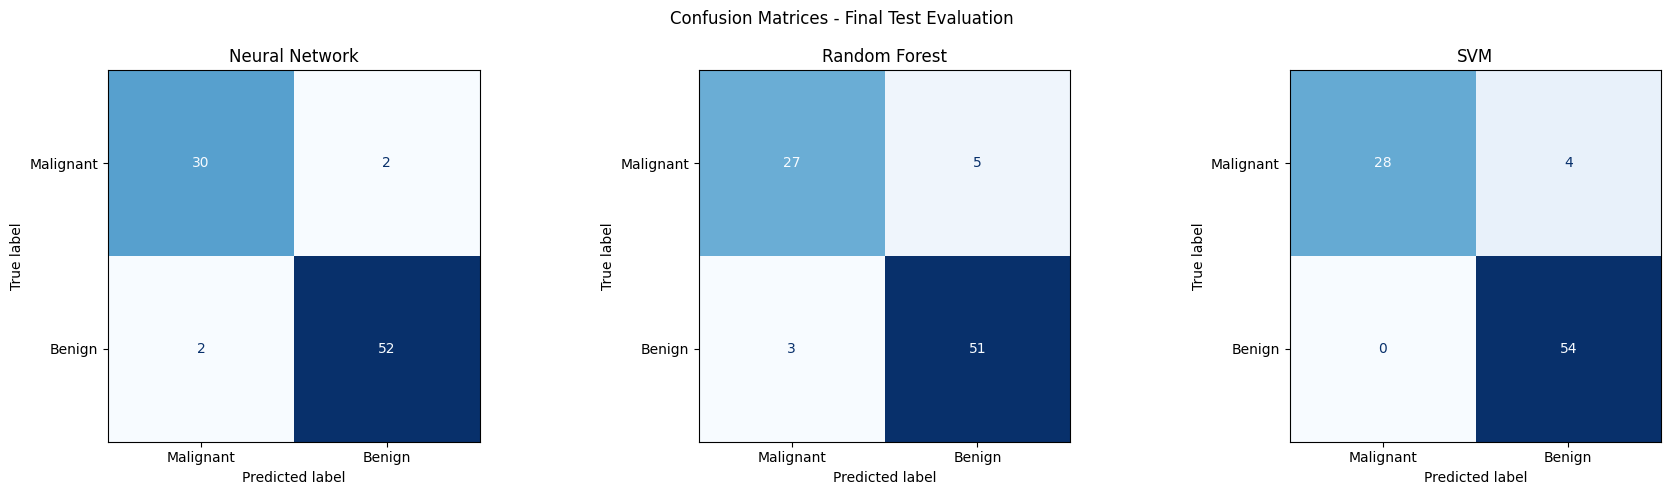

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Neural Network": nn_test_pred,
    "Random Forest": rf_test_pred,
    "SVM": svm_test_pred
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices - Final Test Evaluation")
plt.tight_layout()

plt.savefig(
    "figures/final_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

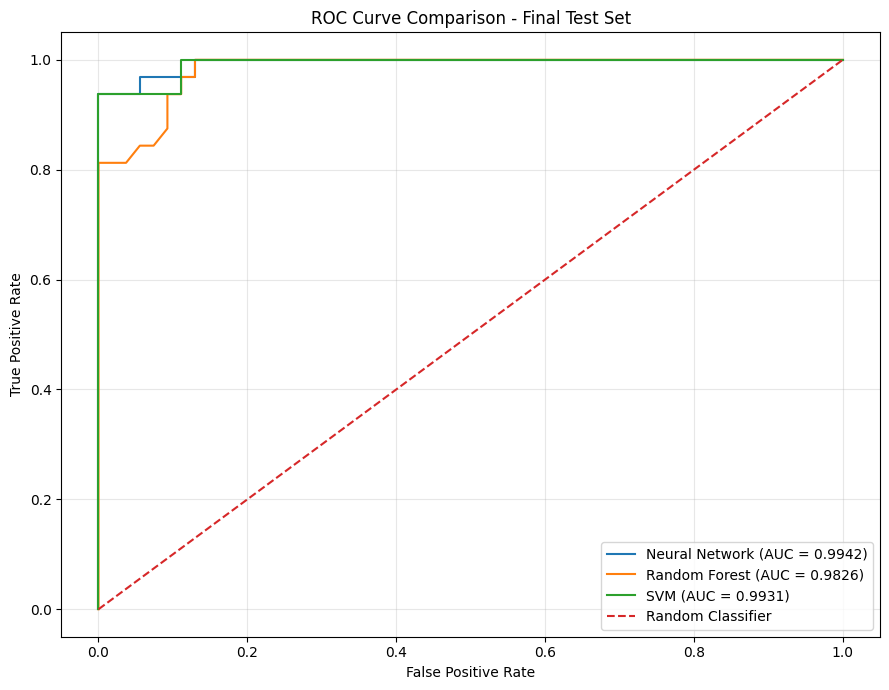

In [35]:
from sklearn.metrics import roc_curve, auc

y_test_malignant = (y_test == 0).astype(int)

roc_scores = {
    "Neural Network": 1 - nn_test_prob,
    "Random Forest": 1 - rf_test_prob,
    "SVM": -svm_test_scores
}

plt.figure(figsize=(9, 7))

for name, scores in roc_scores.items():
    fpr, tpr, thresholds = roc_curve(
        y_test_malignant,
        scores
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Final Test Set")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/final_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

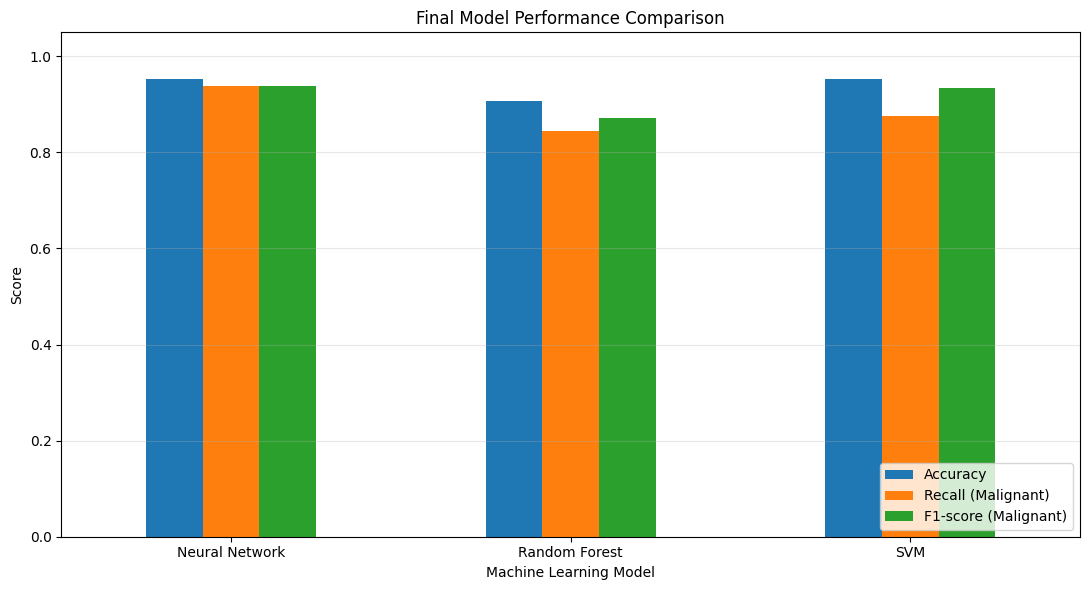

In [36]:
comparison_plot = final_results.set_index("Model")[
    ["Accuracy", "Recall (Malignant)", "F1-score (Malignant)"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()